
![](https://i.imgur.com/SLsD15L.png)



![](https://i.imgur.com/tuZVobx.png)



<div style = "color: Black; display: fill;
              border-radius: 7px;
              background-color: #11456c;
              font-size: 160%;
              font-family: Verdana">
    <p style = "padding: 15px; color: White;"><b> Model (Train) & (Validation)

        

In [1]:
# Import necessary libraries
import sys
import os
sys.path.append('../..')  
import keras
from reid.similarity import CosineSimilarity, similarity_loss, similarity_recall, similarity_scores
from reid.model import create_model
from reid.data import *
from config import dataset_path, MODEL_SAVE_BEST, MODEL_SAVE_LAST
import seaborn as sns

# ----------------------------------
#       Prepare the datasets        |
# ----------------------------------
# Prepare the datasets Function from data.py 
#and facilitate direct usage.
if __name__ == "__main__":
    # The dataset path
    # Call the function to prepare the datasets.
    train_ds, val_ds = prepare_datasets(dataset_path)
    print("Training and validation datasets have been prepared.")

# ----------------------------------
#       Create model                |
# ----------------------------------
# Start create model from model.py
model = create_model()
model.summary()  

# Optimizing the training process with callbacks
model_callbacks = [
    keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, verbose=1),
    keras.callbacks.ModelCheckpoint(MODEL_SAVE_BEST, monitor='val_loss', save_best_only=True, verbose=1),
    keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=5, min_lr=0.001, verbose=1),
    keras.callbacks.TensorBoard(log_dir='./logs', histogram_freq=1)
]

# ----------------------------------
#       Training Section            | Train the model on the dataset
# ----------------------------------
# Start training
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=13,
    callbacks=model_callbacks
)

Training and validation datasets have been prepared.


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape              ┃    Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━┩
│ resnet50 (Functional)           │ (None, 8, 8, 2048)        │ 23,587,712 │
├─────────────────────────────────┼───────────────────────────┼────────────┤
│ global_average_pooling2d        │ (None, 2048)              │          0 │
│ (GlobalAveragePooling2D)        │                           │            │
├─────────────────────────────────┼───────────────────────────┼────────────┤
│ cosine_similarity               │ (None, None)              │          0 │
│ (CosineSimilarity)              │                           │            │
└─────────────────────────────────┴───────────────────────────┴────────────┘

 Total params: 23,587,712 (89.98 MB)

 Trainable params: 23,534,592 (89.78 MB)

 Non-trainable params: 53,120 (207.50 KB)

Epoch 1/13
486/486 ━━━━━━━━━━━━━━━━━━━━ 0s 10s/step - loss: 0.6263 - similarity_recall: 0.3626
Epoch 1: val_loss improved from inf to 0.72681, saving model to /Users/a1443/tensorflow-test/project/reid/runs/D2W0.5/best_model.keras
486/486 ━━━━━━━━━━━━━━━━━━━━ 4926s 10s/step - loss: 0.6262 - similarity_recall: 0.3624 - val_loss: 0.7268 - val_similarity_recall: 0.6987 - learning_rate: 0.0010
Epoch 2/13
486/486 ━━━━━━━━━━━━━━━━━━━━ 0s 9s/step - loss: 0.5158 - similarity_recall: 0.2741
Epoch 2: val_loss did not improve from 0.72681
486/486 ━━━━━━━━━━━━━━━━━━━━ 4423s 9s/step - loss: 0.5158 - similarity_recall: 0.2740 - val_loss: 0.8066 - val_similarity_recall: 0.7099 - learning_rate: 0.0010
Epoch 3/13
486/486 ━━━━━━━━━━━━━━━━━━━━ 0s 10s/step - loss: 0.4985 - similarity_recall: 0.2632 
Epoch 3: val_loss did not improve from 0.72681
486/486 ━━━━━━━━━━━━━━━━━━━━ 5018s 10s/step - loss: 0.4985 - similarity_recall: 0.2632 - val_loss: 0.9318 - val_similarity_recall: 0.7419 - learning_rate: 0.0010
E

In [ ]:
import tensorflow
print(tensorflow.__version__)
import keras
print(keras.__version__)
import sys
import platform
print("Python version:", sys.version)
# Or
print("Python version:", platform.python_version())

In [ ]:
%load_ext tensorboard

## Model save

In [ ]:
model.save(MODEL_SAVE_LAST)


<div style = "color: Black; display: fill;
              border-radius: 7px;
              background-color: #11456c;
              font-size: 160%;
              font-family: Verdana">
    <p style = "padding: 15px; color: White;"><b> Plot (Train) & (Validation)

        

In [ ]:
import matplotlib.pyplot as plt

# Plot the training accuracy and validation accuracy
plt.figure(figsize=(10, 5))
plt.plot(history.history['similarity_recall'], label='Training Similarity Recall')
plt.plot(history.history['val_similarity_recall'], label='Validation Similarity Recall')
plt.title('Training and Validation Similarity Recall')
plt.xlabel('Epochs')
plt.ylabel('Similarity Recall')
plt.legend()
plt.show()
#Calculate the highest value for training accuracy and validation accuracy
max_training_accuracy = max(history.history['similarity_recall'])
max_validation_accuracy = max(history.history['val_similarity_recall'])

# Display the highest value for training accuracy and validation accuracy
print(f'Training Similarity Recall: {max_training_accuracy*100:.2f}%')
print(f'Validation Similarity Recall: {max_validation_accuracy*100:.2f}%')



<div style = "color: Black; display: fill;
              border-radius: 7px;
              background-color: #11456c;
              font-size: 160%;
              font-family: Verdana">
    <p style = "padding: 15px; color: White;"><b> Test load weights Models after Training

        

In [ ]:
import matplotlib.pyplot as plt

model.load_weights(MODEL_SAVE_LAST)
same_scores, diff_scores = similarity_scores(model, val_ds)
plt.hist(same_scores, label='same', alpha=0.5)
plt.hist(diff_scores, label='diff', alpha=0.5)
plt.legend() 
plt.show()

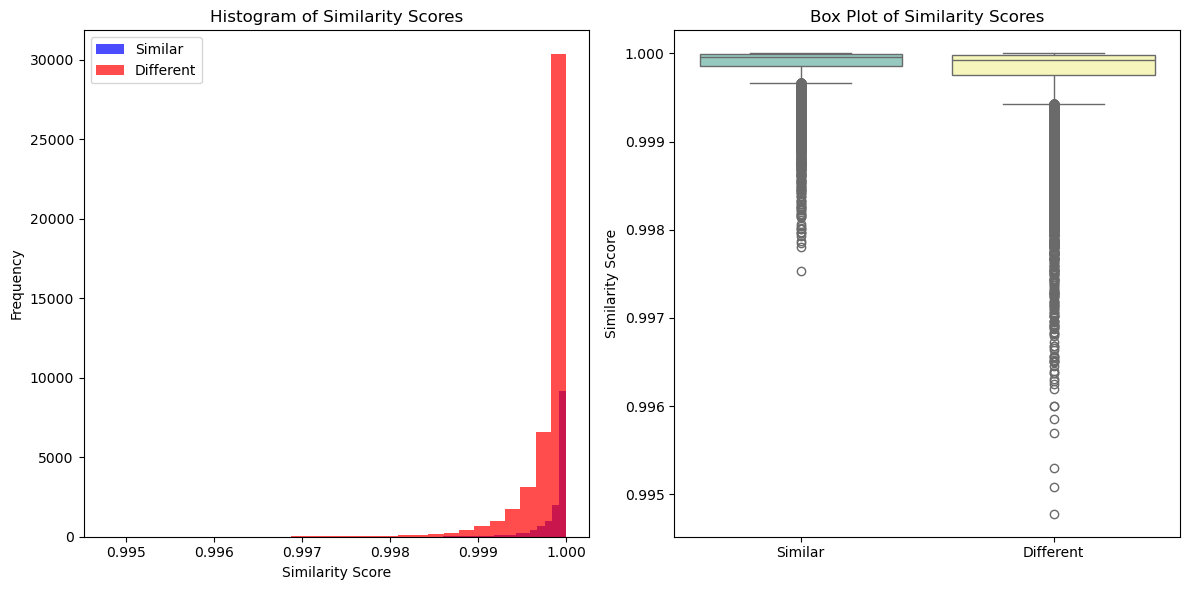

In [ ]:

# Visualization
plt.figure(figsize=(12, 6))

# Histogram
plt.subplot(1, 2, 1)
plt.hist(same_scores, bins=30, alpha=0.7, color='blue', label='Similar') 
plt.hist(diff_scores, bins=30, alpha=0.7, color='red', label='Different') 
plt.title('Histogram of Similarity Scores')
plt.xlabel('Similarity Score')
plt.ylabel('Frequency')
plt.legend()

# Box Plot
plt.subplot(1, 2, 2)
sns.boxplot(data=[same_scores, diff_scores], palette="Set3")
plt.xticks([0, 1], ['Similar', 'Different'])
plt.title('Box Plot of Similarity Scores')
plt.ylabel('Similarity Score')

plt.tight_layout()
plt.show()


## hard diff mask

In [ ]:
model.load_weights(MODEL_SAVE_LAST)
#model.load_weights('last_model copy.keras')

for images, labels in val_ds:
    similarity = model(images).numpy()
    hard_diff_mask = (labels == 0) & (similarity > 0.75)
    if hard_diff_mask.any():
        pairs = np.stack(np.where(hard_diff_mask), axis=-1)
        break

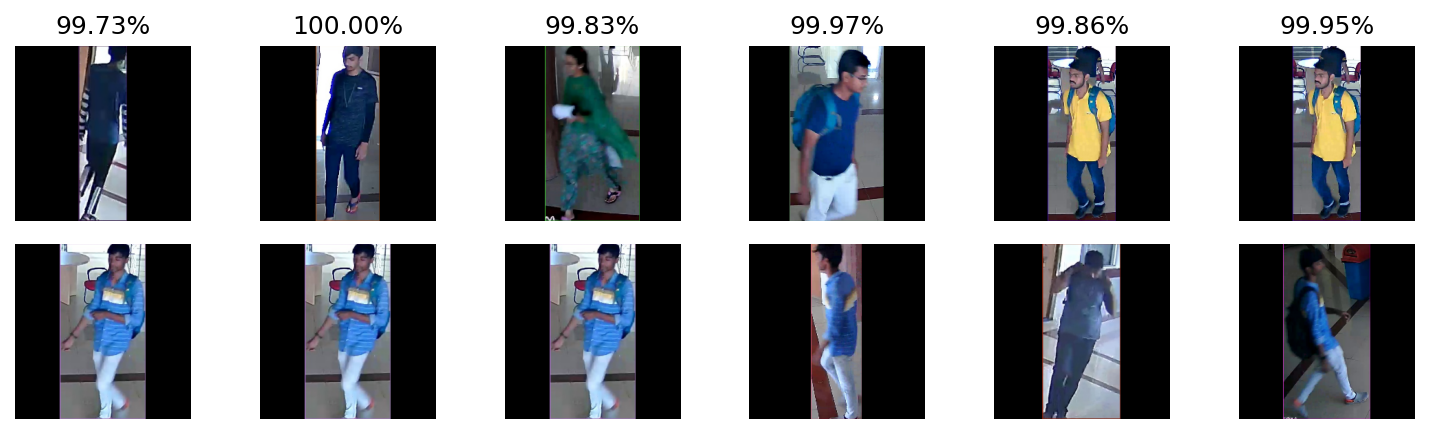

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, min(len(pairs), 6), figsize=(10, 3), dpi=150)
for ax, pair in zip(axes.T, pairs[np.random.permutation(len(pairs))]):
    pair = tuple(pair)
    ax[0].imshow(Image.fromarray(images[pair[0]].astype('uint8')))
    ax[1].imshow(Image.fromarray(images[pair[1]].astype('uint8')))
    ax[0].set_title(f"{similarity[pair]:.2%}")
    ax[0].axis('off')
    ax[1].axis('off')
fig.tight_layout()
plt.show(fig)

## hard same mask

In [ ]:
for images, labels in val_ds:
    similarity = model(images).numpy()
    hard_same_mask = (labels == 1) & (similarity < 0.3)
    if hard_same_mask.any():
        pairs = np.stack(np.where(hard_same_mask), axis=-1)
        break
 

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, min(len(pairs), 6), figsize=(10, 3), dpi=150)
for ax, pair in zip(axes.T, pairs[np.random.permutation(len(pairs))]):
    pair = tuple(pair)
    ax[0].imshow(Image.fromarray(images[pair[0]].astype('uint8')))
    ax[1].imshow(Image.fromarray(images[pair[1]].astype('uint8')))
    ax[0].set_title(f"{similarity[pair]:.2%}")
    ax[0].axis('off')
    ax[1].axis('off')
fig.tight_layout()
plt.show(fig)

In [ ]:
from tqdm.auto import tqdm
import numpy as np 
import matplotlib.pyplot as plt  
dataset = ReID_Dataset(path='/Users/a1443/tensorflow-test/project/Data/Dataset/Dataset_test', batch_size=16, image_size=(256,256))


In [ ]:
# Datasets file path 
print(dataset.__len__())
THRESHOLD = 0.5

total = recall = 0
for images, labels in tqdm(dataset):
    similarity = model(images) # predict 
    recall += similarity_recall(labels, similarity, THRESHOLD) * len(images)
    total += len(images)
recall /= total

print(f"Test Recall = {recall:.2%}")